# Credit Card Fraud Detection

Our goal is to recognize fraudulent credit card transactions.

## Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns; # sns.set()

from imblearn import FunctionSampler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import IsolationForest
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import PrecisionRecallDisplay
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import KFold
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMClassifier
from time import time
from xgboost import XGBClassifier

pd.set_option('display.max_columns', None)

## Load data

In [2]:
df = pd.read_csv("creditcard.csv")

## Peek data

In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Data summary

The dataset contains only numerical features, which, except for `Time` and `Amount`, are the result of a Principal Component Analysis (PCA). We can also see that, except for the target, all features are floats and that there are no missing values.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

## EDA

Let's conduct an exploratory data analysis to try to better understand the nature of the problem.

### Target count

To begin with, this is a classification problem with a highly imbalanced dataset where frauds represent less than 0.2% of all transactions.

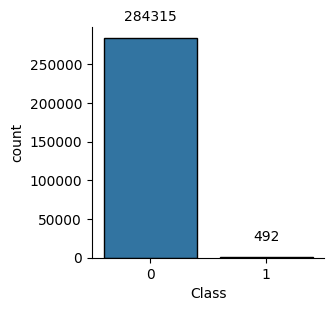

In [5]:
plt.figure(figsize=(3, 3))
ax = sns.countplot(data=df, x="Class", ec="black")
ax.bar_label(ax.containers[0], padding=10)
sns.despine()

### Feature distribution

Some of the variables are more normally distributed (e.g., `V9` and `V13`) and some are more heavy-tailed (e.g., `V28` and `Amount`). There doesn't seem to be anything inherently wrong, though it's hard to know for sure, since, for the most part, we don't have the original variables, only the principal components.

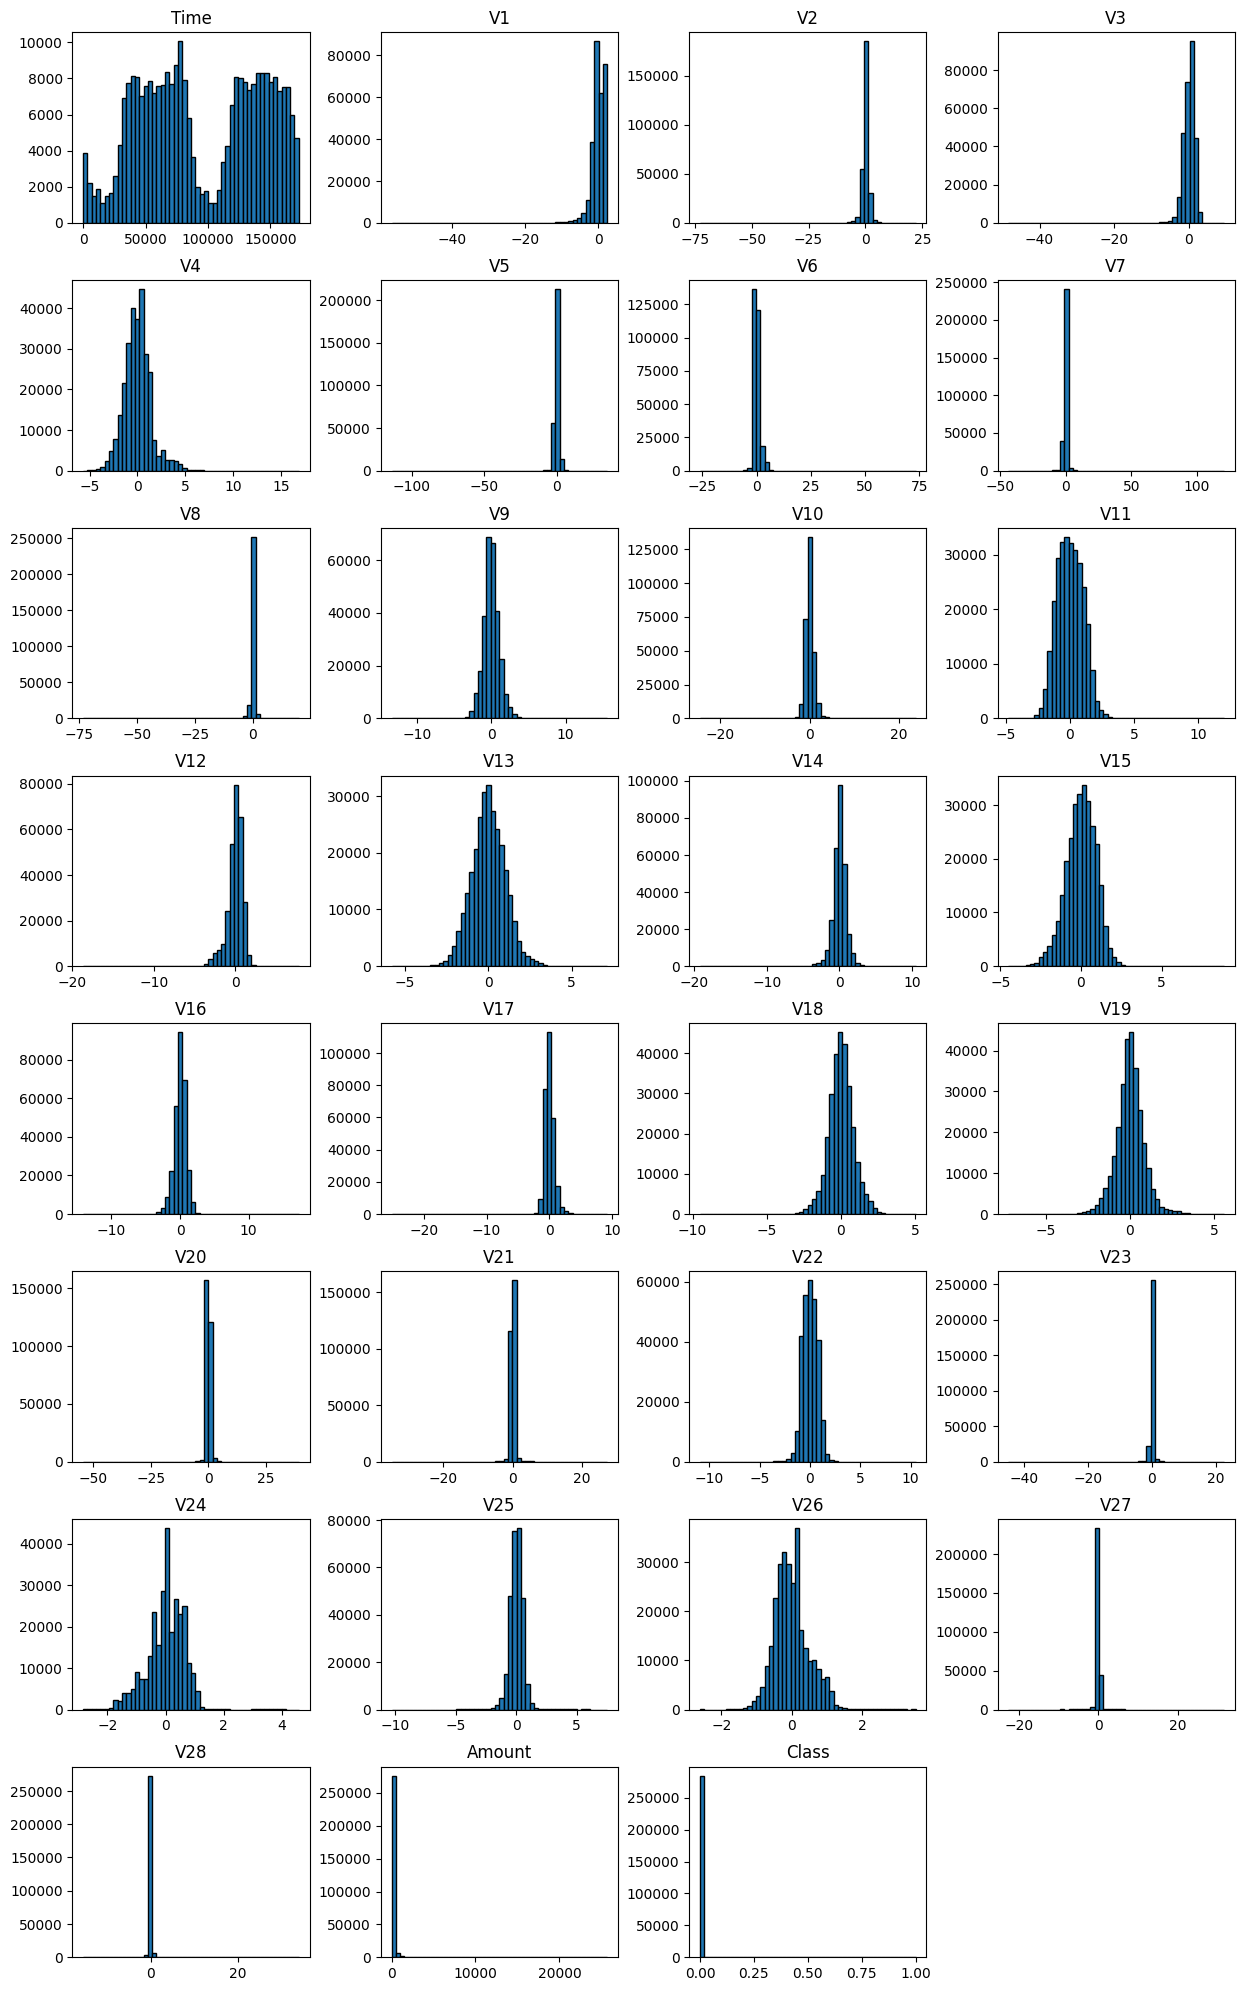

In [6]:
_ = df.hist(figsize=(15, 25), layout=(8, 4), grid=False, ec="black", bins=50)

### Feature distribution by `Class`

We can see that some of the features (e.g., `V11` and `V17`) separate the classes pretty well, which is a pretty good signal that our independent features are useful for predicting the target value. Let's also go ahead and take a look at the features correlations.

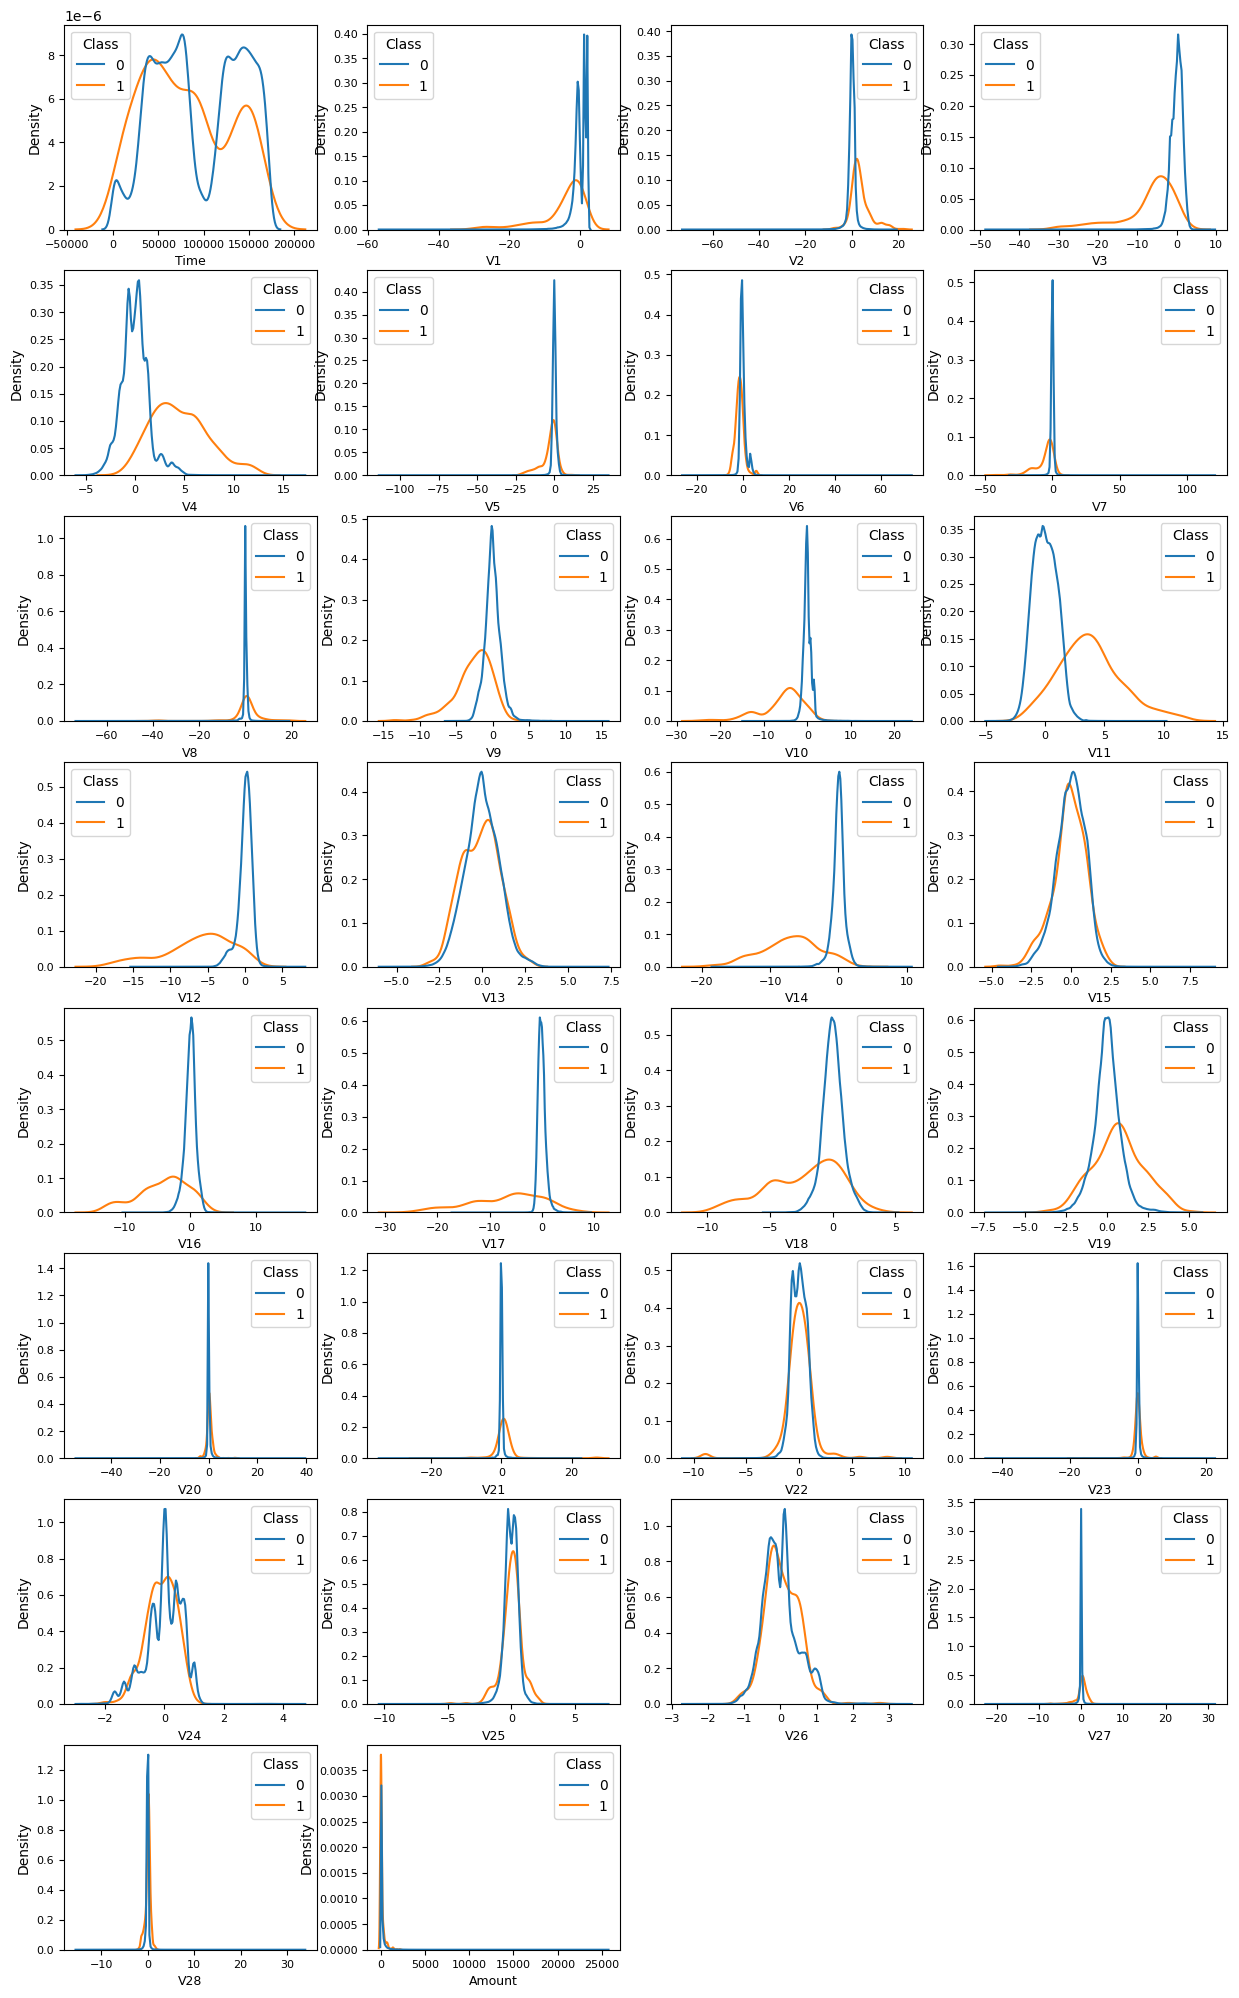

In [7]:
i = 0
nrows = 8
ncols = 4
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 25))
[ax.set_axis_off() for ax in axes.ravel()]  # turn off all axes

for col in df.columns[:-1]:
    plt.subplot(nrows, ncols, i + 1)
    sns.kdeplot(
        data=df, x=col, hue="Class", warn_singular=False, common_norm=False
    )
    plt.xlabel(col, fontsize=9)
    plt.tick_params(axis="x", labelsize=8)
    plt.tick_params(axis="y", labelsize=8)
    axes[i // ncols][i % ncols].set_axis_on()
    i += 1

_ = plt.show()

### Correlations

We can see that most variables are not correlated, that makes sense, since most of them are principal components, which are supposed to be uncorrelated.

In [8]:
corr_matrix = df.corr().round(2)

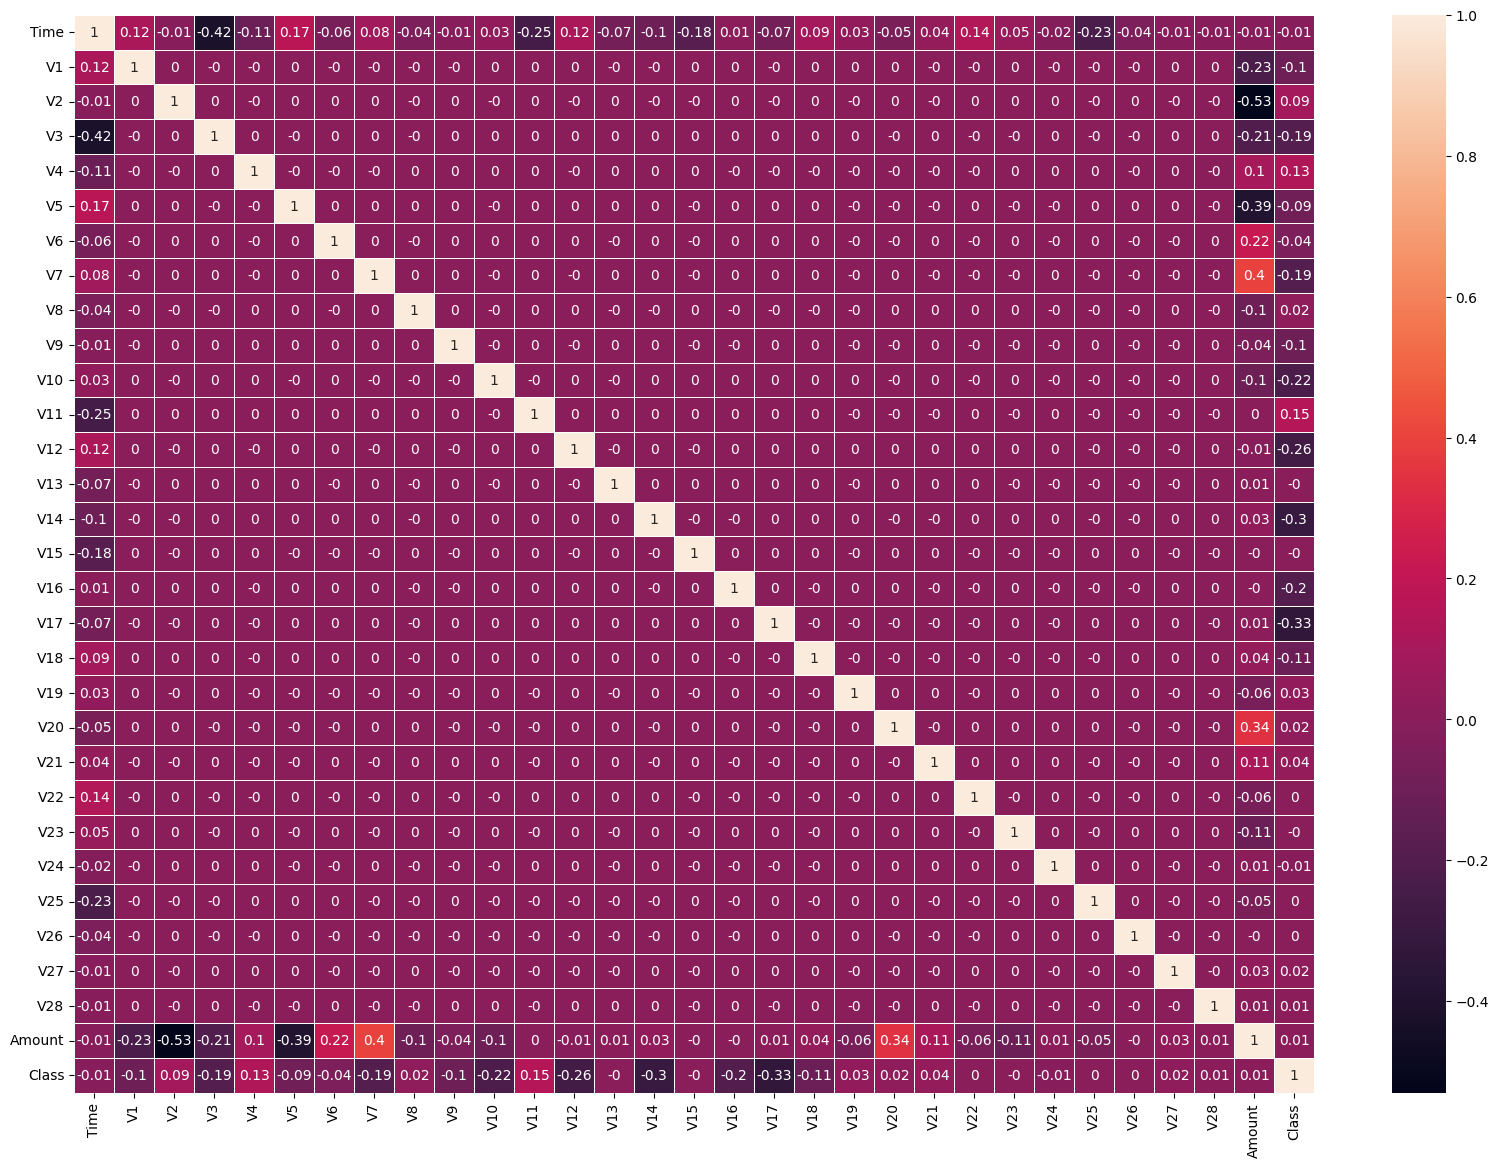

In [9]:
fig, ax = plt.subplots(figsize = (20, 14))
g = sns.heatmap(corr_matrix, linewidths=.5, annot=True, ax=ax)

Taking a closer look at the correlation with the target, we can see that even the strongest correlations (both positive and negative) are somewhat weak.

In [10]:
corr_class = corr_matrix["Class"].sort_values(ascending=True)[:-1]

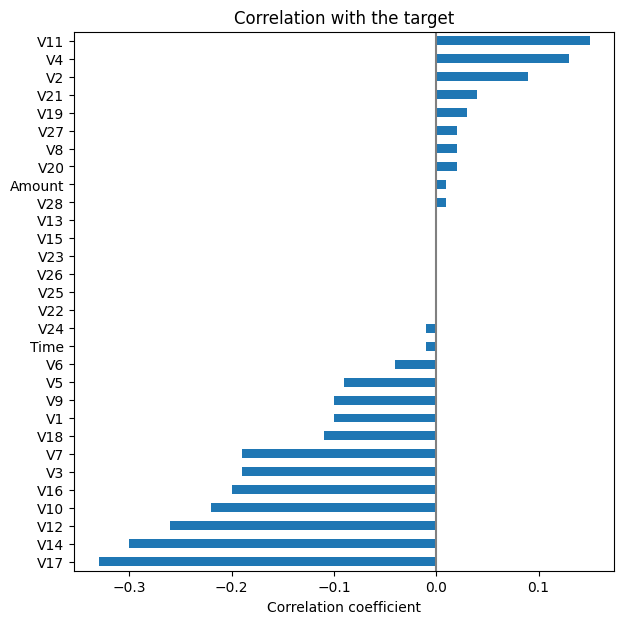

In [11]:
corr_class.plot.barh(figsize=(9, 7))
plt.title("Correlation with the target")
plt.axvline(x=0, color=".5")
plt.xlabel("Correlation coefficient")
plt.subplots_adjust(left=0.3)

How about correlation with the `Amount`, which is the other feature that shows some correlation with the anonymized features? We have 3 features (`V7`, `V5` and, `V2`) with a stronger (perhaps moderate) association, but probably not strong enough to make any of them redundant.

In [12]:
corr_amount = corr_matrix["Amount"].sort_values(ascending=True)[:-1]

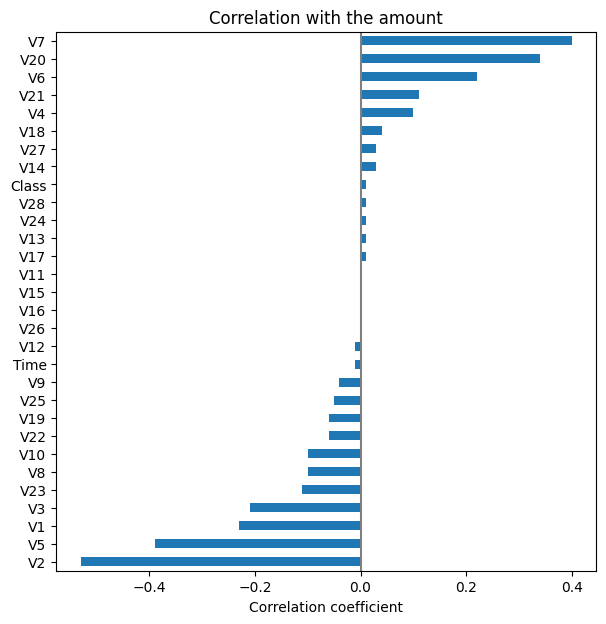

In [13]:
corr_amount.plot.barh(figsize=(9, 7))
plt.title("Correlation with the amount")
plt.axvline(x=0, color=".5")
plt.xlabel("Correlation coefficient")
plt.subplots_adjust(left=0.3)

We can also see that some of the features have weak/moderate monotonic relationship. Based on these results we don't seem to have any redundant variables. Some of the variables are weakly correlated with the target or not correlated at all, so perhaps we can discard some of them. We will experiment with other feature selection techniques later on to see if that's the case.

In [14]:
corr_spearman = df.corr(method="spearman").round(2)

In [15]:
corr_amount_spearman = corr_spearman["Amount"].sort_values(ascending=True)[:-1]

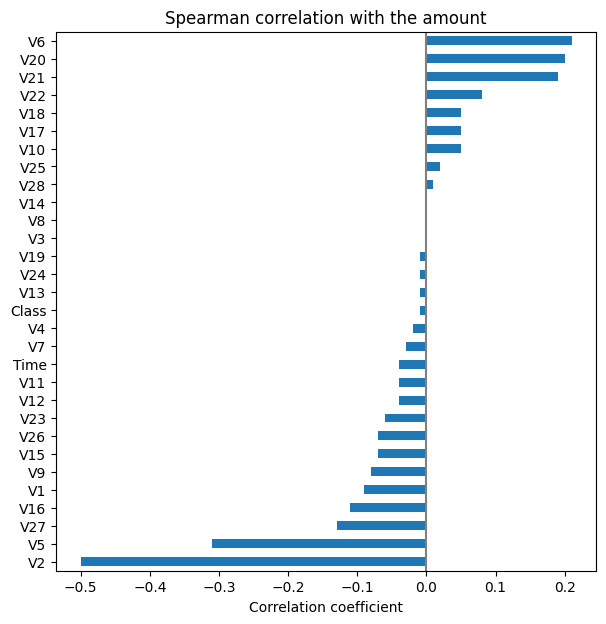

In [16]:
corr_amount_spearman.plot.barh(figsize=(9, 7))
plt.title("Spearman correlation with the amount")
plt.axvline(x=0, color=".5")
plt.xlabel("Correlation coefficient")
plt.subplots_adjust(left=0.3)

### Box plots

Using box plots to take a closer look on some of those features that are most correlated with the `Class`, we can see that *higher* values of `V11` and `V4` are more likely to be a fraud. Conversely, *smaller* values of `V16`, `V7`, `V3`, `V10`, `V12`, `V14`, `V17` are more likely to be a fraud.

In [17]:
# get most correlated features with the class
cols = corr_matrix["Class"].abs().sort_values(ascending=False)[1:10].index
cols

Index(['V17', 'V14', 'V12', 'V10', 'V16', 'V3', 'V7', 'V11', 'V4'], dtype='object')

In [18]:
# cols = ["V11", "V4", "V16", "V7", "V3", "V10", "V12", "V14", "V17"]

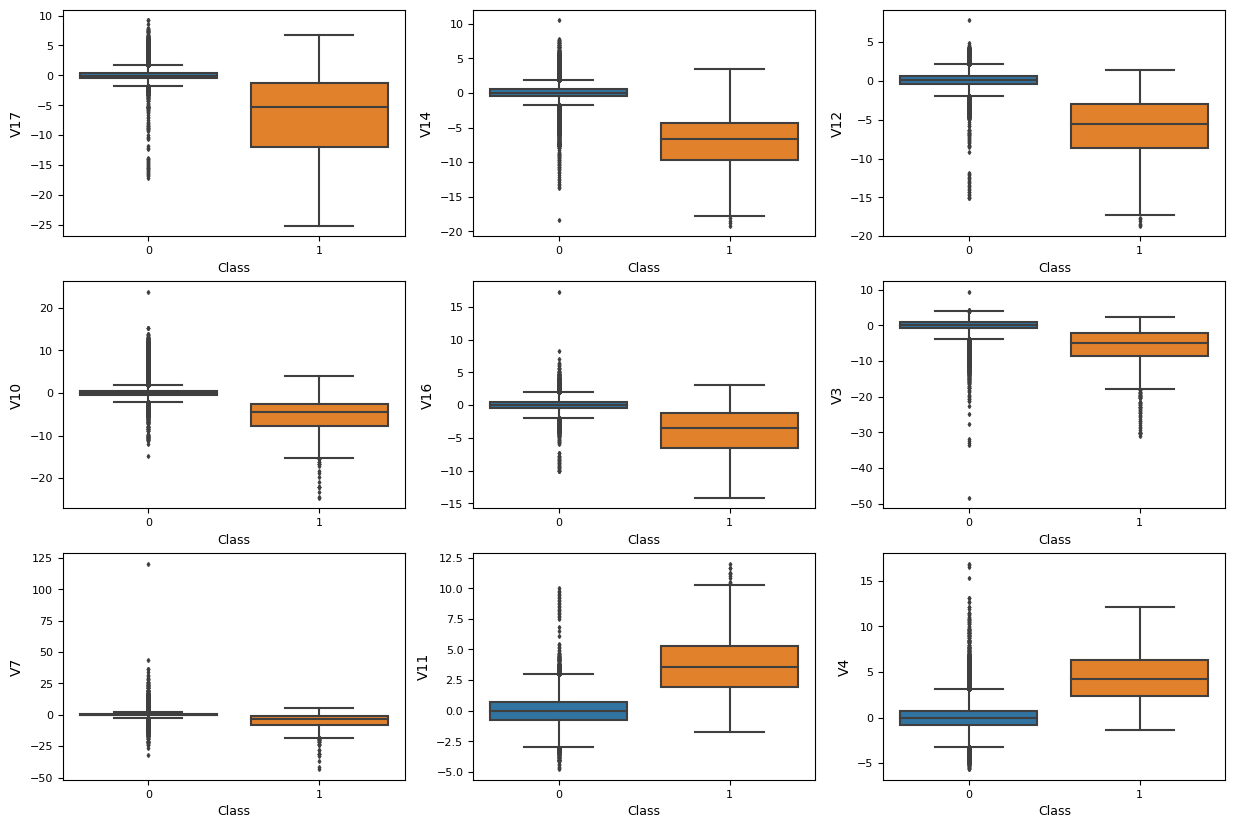

In [19]:
i = 0
nrows = 3
ncols = 3
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 10))

for col in cols:
    plt.subplot(nrows, ncols, i + 1)
    sns.boxplot(x="Class", y=col, data=df, fliersize=2)
    plt.xlabel("Class", fontsize=9)
    plt.tick_params(axis="x", labelsize=8)
    plt.tick_params(axis="y", labelsize=8)
    i += 1

_ = plt.show()

## Violin plots

We can also plot violin plots of the same features for comparison. Violin plots can be more informative than boxplots, because they also show the probability density of the data.

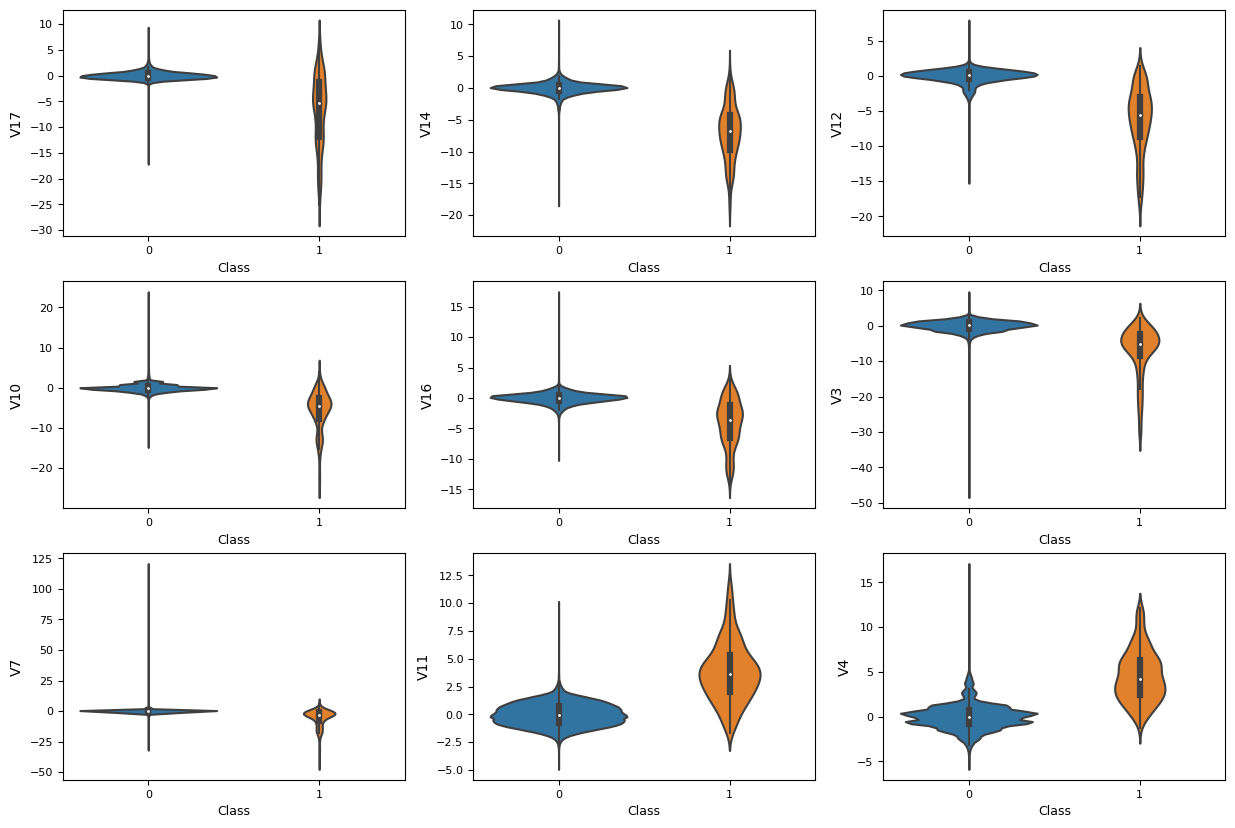

In [20]:
i = 0
nrows = 3
ncols = 3
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 10))

for col in cols:
    plt.subplot(nrows, ncols, i + 1)
    sns.violinplot(x="Class", y=col, data=df, fliersize=2)
    plt.xlabel("Class", fontsize=9)
    plt.tick_params(axis="x", labelsize=8)
    plt.tick_params(axis="y", labelsize=8)
    i += 1

_ = plt.show()

## Train-test split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(["Time", "Class"], axis=1),
    df["Class"],
    test_size=0.2,
    random_state=42,
    stratify=df["Class"],
)

## Metric

Since this is a problem with extremely imbalanced classes *accuracy* is not an appropriate metric, since it does not distinguish between the numbers of correctly classified examples of different classes. The *negative* examples would dominate the metric, but we are more interested in the *positive* examples. *AUC* is one metric that is commonly used when classes are imbalanced, but it would also not be appropriate here, because the huge number of negatives would overshadow changes in the false positive rate (FPR). For the kind of situation we are facing, the *area under the precision-recall curve (AUC-PR)* is the most informative metric, because it will be more sensitive to True Positives, False Positives, and False Negatives than AUC.

## Baseline

Let's start creating a simple classifier that always predicts the most frequent class of a dataset. Our (real) classifier has to perform better than this.

In [22]:
dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(X_train, y_train)

DummyClassifier(strategy='most_frequent')

In [23]:
y_proba = dummy_clf.predict_proba(X_train)

*AP* stands for average precision and is a number that summarizes a precision-recall curve. It's the weighted mean of precisions achieved at each threshold, with the increase in recall from the previous threshold used as the weight. An AP of 0.0, as well as the shape of the curve, indicates that our dummy classifier is random.

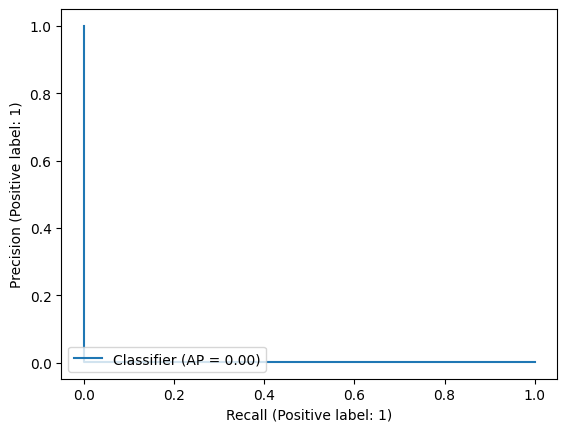

In [24]:
_ = PrecisionRecallDisplay.from_predictions(y_train, y_proba[:, 1])

## Model

### Logistic regression

Let's start with a simpler model. First, we're going to standardize `Amount`. Since the other features are principal components, we assume they have been standardize as well. In fact, we can see that they are all centered around 0, so that seems to be the case. This is an important step, because sklearn logistic regression implementation applies l2 regularization by default and regularization behaves badly without some kind of normalization. The algorithm is also expected to converge faster when features are normalized.

In [25]:
col_transformer = make_column_transformer(
    (StandardScaler(), ["Amount"]),
    remainder="passthrough",
)

Then, let's build a pipeline in which we are going to 

1. detect and flag outliers, 
2. apply the normalization, 
3. do feature selection, 
4. resample the data to make it more balanced and,
5. finally, make predictions using logistic regression.

The feature selection could be done either before or after the resampling ([source](https://ieeexplore.ieee.org/abstract/document/8217782)). For simplicity, let's do it before. Resampling comes in many shapes and forms (imblearn implements several techniques). For brevity, let's focus on two methods, an oversampling one and an undersampling one.

Let's also build a custom estimator for outlier detection, which will flag whether an observation is an outlier, using an algorithm given as a parameter. We could also remove the outliers, flagging is just a more conservative option.

In [26]:
from sklearn.base import BaseEstimator, clone, TransformerMixin

class OutlierDetector(BaseEstimator, TransformerMixin):
    def __init__(self, outlier_detector):
        self.outlier_detector = outlier_detector
        
    def fit(self, X, y=None):
        return self # nothing else to do
    
    def transform(self, X):
        self.outlier_detector_ = clone(self.outlier_detector)
        pred = self.outlier_detector_.fit_predict(X)
        cols = X.columns.to_list()
        cols.append("Outlier")
        return pd.DataFrame(np.c_[X, pred], columns=cols)

In [27]:
lr_pipe = Pipeline(
    steps=[
        ("outlier_detector", "passthrough"),
        ("col_transformer", col_transformer),
        ("feat_selector", "passthrough"),
        ("resampler", "passthrough"),
        ("lr", LogisticRegression(random_state=42)),
    ]
)

Then we can try different types of resampling as well as other logistic regression hyperparameters to see whether our model performs better. 

In [28]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_selection import SelectFromModel

In [29]:
lr_param_grid = [
    {
        "outlier_detector": [
            "passthrough",  # do nothing
            OutlierDetector(IsolationForest(random_state=42)),
        ],
        "feat_selector": [
            SelectKBest(),  # univariate feature selection
        ],
        "resampler": [
            "passthrough",  # do nothing
            SMOTE(random_state=42),  # over-sampling with synthetic samples
            RandomUnderSampler(
                random_state=42
            ),  # random under-sampling without replacement
        ],
        "feat_selector__k": [10, 20, "all"],  # number of features
        "lr__max_iter": [500, 1000],  # max number of iterations
        "lr__solver": ["lbfgs"],  # optimization algorithm
        "lr__penalty": ["l2"],  # type of regularization
        "lr__C": [0.1, 0.5, 1.0],  # regularization strength
    },
    # other parameters we could try, commented out for performance reasons.
#     {
#         "outlier_detector": [
#             "passthrough",  # do nothing
#             OutlierDetector(IsolationForest(random_state=42)),
#         ],
#         "feat_selector": [SelectKBest()],
#         "resampler": [
#             "passthrough",
#             SMOTE(random_state=42),
#             RandomUnderSampler(random_state=42),
#         ],
#         "feat_selector__k": [10, 20, "all"],
#         "lr__max_iter": [500, 1000],
#         "lr__solver": ["saga"],
#         "lr__penalty": ["l1"],
#         "lr__C": [0.1, 0.5, 1.0],
#     },
]


In [30]:
%%time

# randomized search on hyper parameters
lr_grid_search = RandomizedSearchCV(
    lr_pipe,
    param_distributions=lr_param_grid,
    n_iter=10,
    cv=3,
    scoring="average_precision",
    verbose=1,
    refit=True,
    random_state=42,
)
lr_grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
CPU times: user 4min 8s, sys: 34.2 s, total: 4min 42s
Wall time: 4min 50s


RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('outlier_detector',
                                              'passthrough'),
                                             ('col_transformer',
                                              ColumnTransformer(remainder='passthrough',
                                                                transformers=[('standardscaler',
                                                                               StandardScaler(),
                                                                               ['Amount'])])),
                                             ('feat_selector', 'passthrough'),
                                             ('resampler', 'passthrough'),
                                             ('lr',
                                              LogisticRegression(random_state=42))]),
                   param_distributions=[{'feat_selecto...
                                         'feat_selector__k': [10, 20, 'all'],
                                         'lr__C': [0.1, 0.5, 1.0],
                                         'lr__max_iter': [500, 1000],
                                         'lr__penalty': ['l2'],
                                         'lr__solver': ['lbfgs'],
                                         'outlier_detector': ['passthrough',
                                                              OutlierDetector(outlier_detector=IsolationForest(random_state=42))],
                                         'resampler': ['passthrough',
                                                       SMOTE(random_state=42),
                                                       RandomUnderSampler(random_state=42)]}],
                   random_state=42, scoring='average_precision', verbose=1)

In [31]:
# %%time

# exhaustive search over specified parameter values
# we can go through every combination if we have enough time

# lr_grid_search = GridSearchCV(
#     lr_pipe, 
#     lr_param_grid, # parameter values
#     cv=3, # 3-fold cross validation
#     scoring="average_precision", # our metric
#     verbose=1
# )
# lr_grid_search.fit(X_train, y_train)

Now we can see what the best estimator was.

In [32]:
lr_grid_search.best_estimator_

Pipeline(steps=[('outlier_detector',
                 OutlierDetector(outlier_detector=IsolationForest(random_state=42))),
                ('col_transformer',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('standardscaler',
                                                  StandardScaler(),
                                                  ['Amount'])])),
                ('feat_selector', SelectKBest(k=20)),
                ('resampler', 'passthrough'),
                ('lr',
                 LogisticRegression(C=0.1, max_iter=1000, random_state=42))])

And we can see the best parameters as well.

In [33]:
lr_grid_search.best_params_

{'resampler': 'passthrough',
 'outlier_detector': OutlierDetector(outlier_detector=IsolationForest(random_state=42)),
 'lr__solver': 'lbfgs',
 'lr__penalty': 'l2',
 'lr__max_iter': 1000,
 'lr__C': 0.1,
 'feat_selector__k': 20,
 'feat_selector': SelectKBest(k=20)}

What is the best metric achieved?

In [34]:
print("AP:", lr_grid_search.best_score_)

AP: 0.7507473214843768


In [35]:
# get logistic regression coefficients
coef = lr_grid_search.best_estimator_.named_steps.lr.coef_

In [36]:
lr_grid_search.best_estimator_.named_steps

{'outlier_detector': OutlierDetector(outlier_detector=IsolationForest(random_state=42)),
 'col_transformer': ColumnTransformer(remainder='passthrough',
                   transformers=[('standardscaler', StandardScaler(),
                                  ['Amount'])]),
 'feat_selector': SelectKBest(k=20),
 'resampler': 'passthrough',
 'lr': LogisticRegression(C=0.1, max_iter=1000, random_state=42)}

In [37]:
# get feature names
feature_names = lr_grid_search.best_estimator_.named_steps.col_transformer.get_feature_names_out()
feature_names = [feat.split("__")[1] for feat in feature_names]

In [38]:
mask = lr_grid_search.best_estimator_.named_steps.feat_selector.get_support()

In [39]:
feature_names = [feature for bool, feature in zip(mask, feature_names) if bool]

In [40]:
coefs = pd.DataFrame(
    coef[0],
    columns=["Coefficients"],
    index=feature_names,
)

We can plot the coefficients to better inspect their magnitudes.

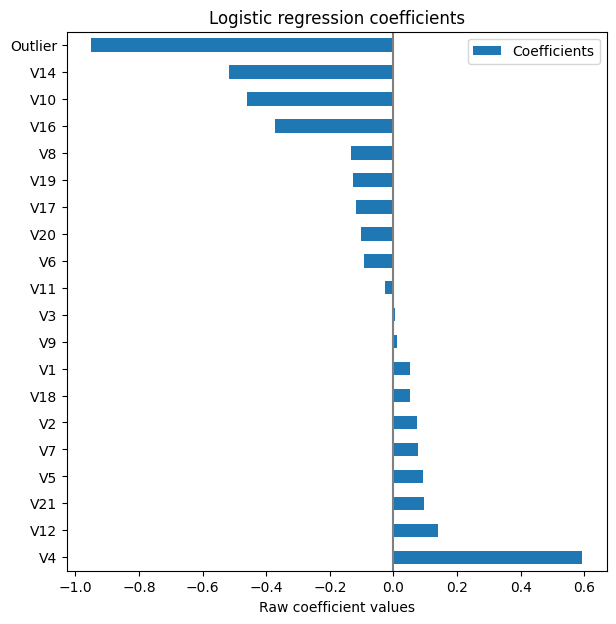

In [41]:
coefs_sorted = coefs.sort_values(by="Coefficients", ascending=False)
coefs_sorted.plot.barh(figsize=(9, 7))
plt.title("Logistic regression coefficients")
plt.axvline(x=0, color=".5")
plt.xlabel("Raw coefficient values")
plt.subplots_adjust(left=0.3)

The interpretation is increasing a predictor $X_i$ by one unit multiplies the odds of having the outcome by $e^{\beta_i}$.

In [42]:
y_proba = lr_grid_search.predict_proba(X_test)

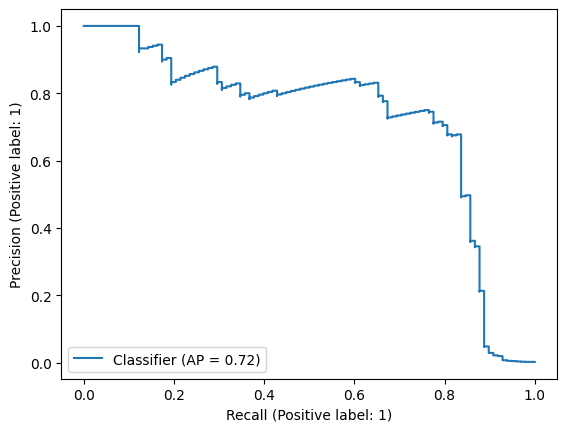

In [43]:
_ = PrecisionRecallDisplay.from_predictions(y_test, y_proba[:, 1])

In [44]:
y_pred = lr_grid_search.predict(X_test)

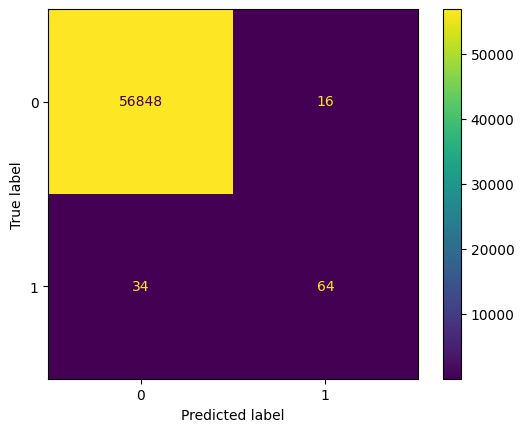

In [45]:
_ = ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

In [46]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.80      0.65      0.72        98

    accuracy                           1.00     56962
   macro avg       0.90      0.83      0.86     56962
weighted avg       1.00      1.00      1.00     56962



### LightGBM

Now we can try a more complex model. The pipeline is similar, except for the final classifier.

In [47]:
xgb_pipe = Pipeline(
    steps=[
        ("outlier_detector", "passthrough"),
        ("col_transformer", col_transformer),
        ("feat_selector", "passthrough"),
        ("resampler", "passthrough"),
        (
            "xgb",
            LGBMClassifier(),
        ),
    ]
)

In [48]:
param_distributions = {
    "outlier_detector": [
        "passthrough",
        OutlierDetector(IsolationForest(random_state=42)),
    ],
    "feat_selector": [
        "passthrough",
        SelectFromModel(
            LogisticRegression(random_state=42)
        ),  # feature selection based on importance weights
    ],
    "resampler": [
        "passthrough",
        SMOTE(random_state=42), # over-sampling with synthetic samples
        RandomUnderSampler(random_state=42), # random under-sampling without replacement
    ],
    "xgb__max_depth": [3, 5, 6, 10, 15, 20], # limit the tree depth
    "xgb__learning_rate": [0.01, 0.1, 0.2, 0.3], # shrinkage
    "xgb__subsample": np.arange(0.5, 1.0, 0.1), # ratio of training instances
    "xgb__colsample_bytree": np.arange(0.4, 1.0, 0.1), # ratio of columns for each tree
    "xgb__n_estimators": [100, 500, 1000], # number of trees to fit
}

We have more parameters and hence more combinations, so instead of exhaustively searching, let's try a random search. Raising the number of iterations, increases runtime, but may result in a better solution.

In [49]:
%%time

# randomized search on hyper parameters
xgb_grid_search = RandomizedSearchCV(
    xgb_pipe,
    param_distributions=param_distributions,
    n_iter=15,
    cv=3,
    scoring="average_precision",
    verbose=1,
    refit=True,
    random_state=42,
)
xgb_grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
CPU times: user 13min 40s, sys: 44.2 s, total: 14min 24s
Wall time: 1h 5min 36s


RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('outlier_detector',
                                              'passthrough'),
                                             ('col_transformer',
                                              ColumnTransformer(remainder='passthrough',
                                                                transformers=[('standardscaler',
                                                                               StandardScaler(),
                                                                               ['Amount'])])),
                                             ('feat_selector', 'passthrough'),
                                             ('resampler', 'passthrough'),
                                             ('xgb', LGBMClassifier())]),
                   n_iter=15,
                   param_distributions={'feat_selector': ['pass...
                                        'resampler': ['passthrough',
                                                      SMOTE(random_state=42),
                                                      RandomUnderSampler(random_state=42)],
                                        'xgb__colsample_bytree': array([0.4, 0.5, 0.6, 0.7, 0.8, 0.9]),
                                        'xgb__learning_rate': [0.01, 0.1, 0.2,
                                                               0.3],
                                        'xgb__max_depth': [3, 5, 6, 10, 15, 20],
                                        'xgb__n_estimators': [100, 500, 1000],
                                        'xgb__subsample': array([0.5, 0.6, 0.7, 0.8, 0.9])},
                   random_state=42, scoring='average_precision', verbose=1)

In [50]:
xgb_grid_search.best_estimator_

Pipeline(steps=[('outlier_detector', 'passthrough'),
                ('col_transformer',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('standardscaler',
                                                  StandardScaler(),
                                                  ['Amount'])])),
                ('feat_selector',
                 SelectFromModel(estimator=LogisticRegression(random_state=42))),
                ('resampler', 'passthrough'),
                ('xgb',
                 LGBMClassifier(colsample_bytree=0.7999999999999999,
                                learning_rate=0.01, max_depth=5,
                                n_estimators=500,
                                subsample=0.7999999999999999))])

In [51]:
xgb_grid_search.best_params_

{'xgb__subsample': 0.7999999999999999,
 'xgb__n_estimators': 500,
 'xgb__max_depth': 5,
 'xgb__learning_rate': 0.01,
 'xgb__colsample_bytree': 0.7999999999999999,
 'resampler': 'passthrough',
 'outlier_detector': 'passthrough',
 'feat_selector': SelectFromModel(estimator=LogisticRegression(random_state=42))}

In [52]:
print("AP:", xgb_grid_search.best_score_)

AP: 0.8173400074322598


In [53]:
# get feature importances
importance = xgb_grid_search.best_estimator_.named_steps.xgb.feature_importances_

In [54]:
# get feature names
feature_names = xgb_grid_search.best_estimator_.named_steps.col_transformer.get_feature_names_out()
feature_names = [feat.split("__")[1] for feat in feature_names]

In [55]:
mask = xgb_grid_search.best_estimator_.named_steps.feat_selector.get_support()

In [56]:
feature_names = [feature for bool, feature in zip(mask, feature_names) if bool]

In [57]:
importances = pd.DataFrame(
    importance,
    columns=["Feature importances"],
    index=feature_names,
)

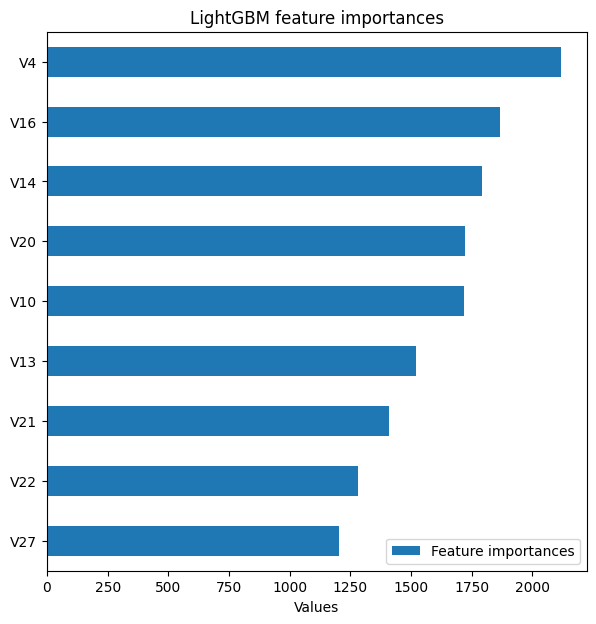

In [58]:
importances_sorted = importances.sort_values(by="Feature importances", ascending=True)
importances_sorted.plot.barh(figsize=(9, 7))
plt.title("LightGBM feature importances")
plt.axvline(x=0, color=".5")
plt.xlabel("Values")
plt.subplots_adjust(left=0.3)

## Evaluation

The boosting model performed better, so now we can evaluate it using the test set.

In [59]:
y_proba = xgb_grid_search.predict_proba(X_test)

### Precision-recall curve

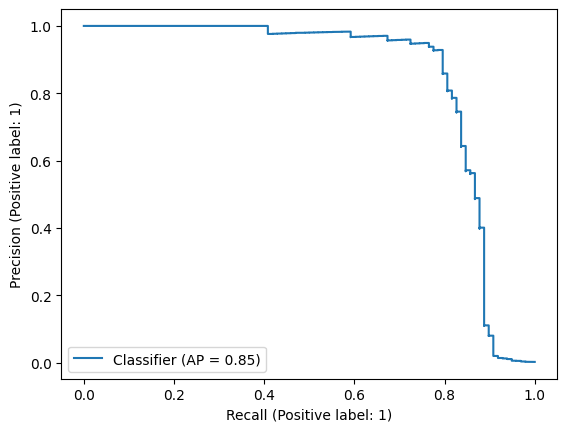

In [60]:
_ = PrecisionRecallDisplay.from_predictions(y_test, y_proba[:, 1])

In [61]:
y_pred = xgb_grid_search.predict(X_test)

### Confusion matrix

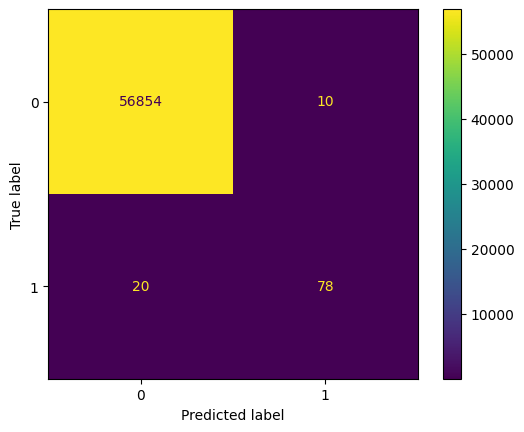

In [62]:
_ = ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

### Classification report

In [63]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.89      0.80      0.84        98

    accuracy                           1.00     56962
   macro avg       0.94      0.90      0.92     56962
weighted avg       1.00      1.00      1.00     56962



## Conclusion

The model performed way better than our baseline. Even with the imbalanced data, it's performing well. We were also able to make good predictions using only a subset of the features, which makes the model simpler and faster to train. We can still try other hyperparameters and techniques for feature selection, resampling, and outlier detection. We can also try different thresholds. It's probably better to detect more frauds, even if we have more false positives, so perhaps it would be better to trade a little precision for better recall. For now, though, we already have a good working model.